In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "raw" / "Task06_Lung"

def nii_files(folder):
    return sorted(p for p in folder.glob("*.nii.gz") if not p.name.startswith("."))

images = nii_files(DATA / "imagesTr")
labels = nii_files(DATA / "labelsTr")
print(len(images), "images,", len(labels), "masks")
assert [p.name for p in images] == [p.name for p in labels]

63 images, 63 masks


In [2]:
img = nib.load(images[0])
lab = nib.load(labels[0])
print(images[0].name)
print("shape:", img.shape)
print("spacing (mm):", img.header.get_zooms())
print("orientation:", nib.aff2axcodes(img.affine))

ct = np.asanyarray(img.dataobj).astype(np.float32)
mask = np.asanyarray(lab.dataobj).astype(np.uint8)
print("CT range:", ct.min(), ct.max())
print("mask values (value, count):", np.unique(mask, return_counts=True))

lung_001.nii.gz
shape: (512, 512, 304)
spacing (mm): (np.float32(0.6933594), np.float32(0.6933594), np.float32(1.0))
orientation: ('L', 'A', 'S')
CT range: -1024.0 3071.0
mask values (value, count): (array([0, 1], dtype=uint8), array([79689057,     2719]))


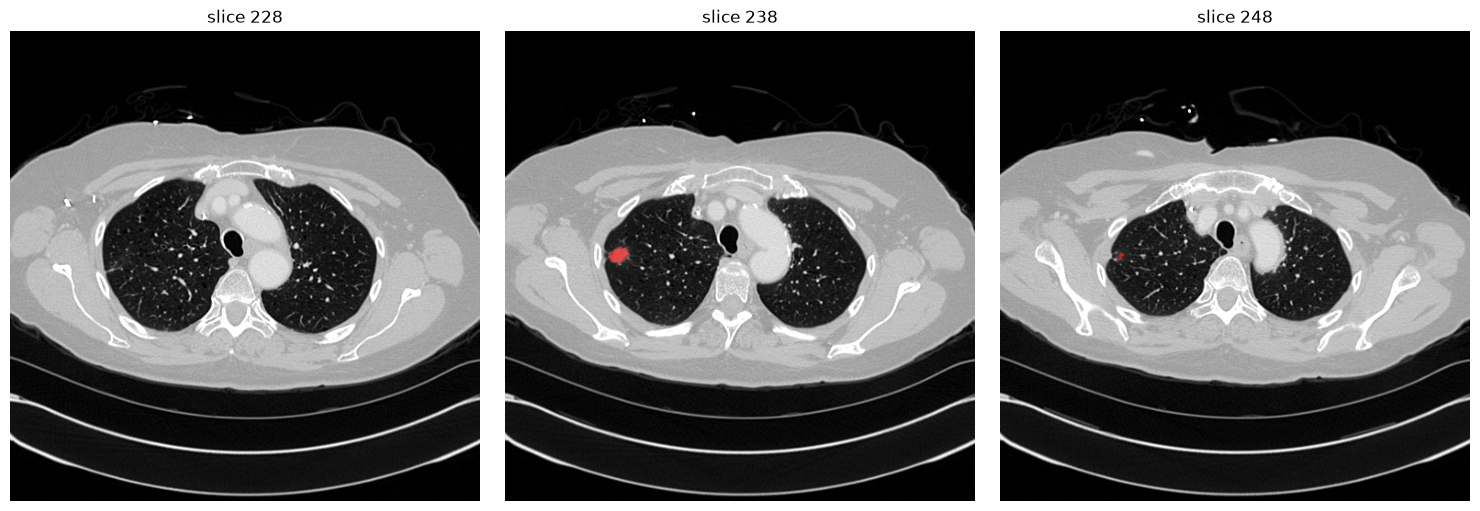

In [3]:
def show_slice(ct, mask, k, ax, window=(-1000, 400)):
    ax.imshow(np.clip(ct[:, :, k], *window).T, cmap="gray", origin="lower")
    m = mask[:, :, k].T
    ax.imshow(np.ma.masked_where(m == 0, m), cmap="autumn", alpha=0.6, origin="lower")
    ax.axis("off")

best = int(mask.sum(axis=(0, 1)).argmax())
ks = [max(best - 10, 0), best, min(best + 10, ct.shape[2] - 1)]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axes, ks):
    show_slice(ct, mask, k, ax)
    ax.set_title(f"slice {k}")
plt.tight_layout()

(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "docs" / "figures" / "example_slices.png", dpi=120)
plt.show()

In [4]:
from tqdm import tqdm

out_csv = ROOT / "data" / "processed" / "case_stats.csv"
out_csv.parent.mkdir(parents=True, exist_ok=True)

rows = []
for ip, lp in tqdm(list(zip(images, labels))):
    h = nib.load(ip)
    m = np.asanyarray(nib.load(lp).dataobj) > 0
    sx, sy, sz = h.header.get_zooms()[:3]
    box = ndimage.find_objects(m.astype(np.uint8))
    if box:
        _, n_comp = ndimage.label(m[box[0]])
    else:
        n_comp = 0
    rows.append({
        "case": ip.name.replace(".nii.gz", ""),
        "n_slices": h.shape[2],
        "spacing_xy": round(float(sx), 2),
        "spacing_z": round(float(sz), 2),
        "tumour_ml": m.sum() * sx * sy * sz / 1000,
        "tumour_fraction": m.mean(),
        "n_components": n_comp,
    })
df = pd.DataFrame(rows)
df.to_csv(out_csv, index=False)
df.describe()

100%|██████████| 63/63 [02:01<00:00,  1.94s/it]


,n_slices,spacing_xy,spacing_z,tumour_ml,tumour_fraction,n_components
count,63.000000,63.000000,63.000000,63.000000,63.000000,63.000000
mean,280.269841,0.793651,1.313810,21.982524,0.000387,2.603175
std,110.869759,0.083537,0.493132,52.071090,0.000777,3.092862
min,112.000000,0.600000,0.620000,0.737738,0.000014,1.000000
25%,240.500000,0.765000,1.240000,2.725717,0.000047,1.000000
50%,252.000000,0.790000,1.240000,5.220032,0.000107,1.000000
75%,298.500000,0.845000,1.250000,15.874925,0.000399,3.000000
max,636.000000,0.980000,2.500000,370.384113,0.005124,14.000000


In [5]:
q1, q3 = df["tumour_ml"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Tukey upper fence: {upper:.1f} ml")
outliers = df[df["tumour_ml"] > upper].sort_values("tumour_ml", ascending=False)
print(len(outliers), "cases above the fence")
outliers[["case", "tumour_ml", "tumour_fraction", "n_components", "spacing_z", "n_slices"]]

Tukey upper fence: 35.6 ml
8 cases above the fence


,case,tumour_ml,tumour_fraction,n_components,spacing_z,n_slices
35,lung_053,370.384113,0.005124,3,1.25,252
17,lung_028,151.340964,0.002230,7,1.25,251
43,lung_064,90.826498,0.002270,1,1.24,248
5,lung_009,89.475402,0.001348,10,1.25,301
19,lung_031,70.776749,0.001442,3,1.25,304
25,lung_041,63.353685,0.001202,1,1.24,240
12,lung_022,59.105733,0.001054,11,0.62,483
44,lung_065,41.447470,0.000936,4,2.50,128


In [6]:
x = np.log10(df["tumour_ml"])

q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
tukey_log = df[(x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)]

med = x.median()
mad = (x - med).abs().median()
mz = 0.6745 * (x - med) / mad
mad_out = df[mz.abs() > 3.5]

print("Tukey on log10:", len(tukey_log), "cases")
print("Modified z-score:", len(mad_out), "cases")
both = set(tukey_log["case"]) & set(mad_out["case"])
print("Flagged by both:", sorted(both))

Tukey on log10: 1 cases
Modified z-score: 0 cases
Flagged by both: []


## Outlier analysis: tumour volume

### Why look at this
The tumour volume per case is very uneven: median 5.2 ml, mean 22.0 ml, standard deviation 52.1 ml, maximum 370.4 ml. Before training, I wanted to know whether a few cases are extreme enough to cause trouble, for example by dominating the metrics or by pointing to annotation errors. Note that the volume adds up all tumour components of a case, so a large value is not necessarily a single mass.

### Method
I flag cases with Tukey's fences: a case is flagged if it lies more than 1.5 times the interquartile range below the first quartile or above the third one. I chose this rule because it is simple, it makes no assumption about the shape of the distribution, and it relies on quartiles rather than on the mean and standard deviation, which are pulled strongly by the largest cases here (the standard deviation is larger than the mean).

Applied to the raw volume, the upper fence is about 35.6 ml (Q1 = 2.73 ml, Q3 = 15.87 ml). That is too strict for this data: tumour sizes span about three orders of magnitude and the distribution is strongly right-skewed, so the rule flags large tumours almost by construction. I therefore applied it to log10(volume), where the distribution is much more symmetric. Result: [N] case(s) flagged, upper fence at [X] ml.

As a cross-check I used the modified z-score (median and median absolute deviation of log10 volume, threshold 3.5). Result: [N] case(s) flagged.

### Other approaches considered
- Percentile-based reference intervals: they flag a fixed share of cases (about 5% for a 95% interval) whatever the data looks like, so they describe the data but do not detect anything.
- Clinical size classes: more meaningful to a radiologist than a statistical cut-off. I will use size classes to report results later, instead of excluding cases.
- Multivariate methods